In [2]:
%pip install pandas numpy matplotlib openpyxl jinja2 seaborn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Lectura del dataset Excel local

df = pd.read_excel('../datos/QualityOfCare.xlsx')

print(f'Dataset cargado: {df.shape[0]} filas y {df.shape[1]} columnas')

Dataset cargado: 27288 filas y 46 columnas


,Variable,Tipo_Python,Valores_No_Nulos,Valores_Nulos,Pct_Nulos,Valores_Unicos
0,Health facility level,str,27288,0,0.0%,3
1,FacilityType,str,27288,0,0.0%,4
2,FundingSources,str,27196,92,0.3%,9
3,DateOfBirth,object,24493,2795,10.2%,10477
4,Age,float64,26569,719,2.6%,113
5,AgeInMonths,float64,642,26646,97.7%,66
6,Sex,str,27288,0,0.0%,2
7,MaritalStatus,str,25547,1741,6.4%,7
8,EducationLevel,str,24638,2650,9.7%,6
9,Occupation,str,24610,2678,9.8%,5


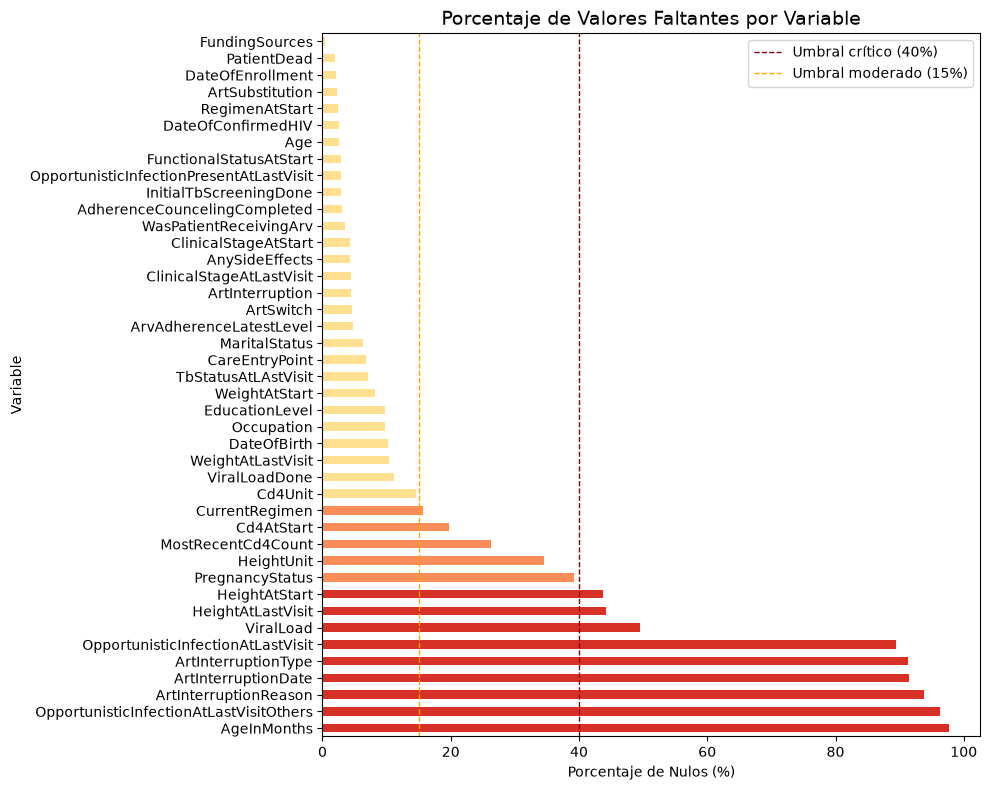

,Conteo,Media,Desv. Estándar,Mínimo,Percentil 25,Mediana,Percentil 75,Máximo,Coef. Variación (%)
Age,26569.00,109.56,12159.49,0.00,27.00,34.00,42.00,1982014.00,11098.57
AgeInMonths,642.00,14.89,80.24,0.00,0.00,2.00,18.00,1987.00,538.82
WeightAtStart,25065.00,54.92,17.12,0.00,47.00,55.00,65.00,100.00,31.18
HeightAtStart,15357.00,142.79,51.77,0.00,150.00,160.00,166.00,980.00,36.26
Cd4AtStart,21906.00,451.51,6625.04,0.00,139.00,267.00,434.00,662645.00,1467.30
WeightAtLastVisit,24444.00,60.01,30.31,0.00,50.00,60.00,69.00,1248.00,50.50
HeightAtLastVisit,15231.00,144.67,335.18,0.00,150.00,160.00,166.00,40914.00,231.69
MostRecentCd4Count,20106.00,654.21,7467.95,0.00,229.00,396.00,600.00,578566.00,1141.52


In [4]:
#Creamos el DataFrame que nos permite visualizar y comprender los elementos de la base de datos:

resumen_variables = pd.DataFrame({

    'Variable': df.columns,                                                   #Asigna cada columna a una fila bajo el nombre de Variable

    'Tipo_Python': df.dtypes.values,                                          #Tipo de dato, detectado por Python

    'Valores_No_Nulos': df.notnull().sum().values,                            #Cantidad de valores no nulos

    'Valores_Nulos': df.isnull().sum().values,                                #Cantidad de valores nulos

    'Pct_Nulos': (df.isnull().mean() * 100).round(2).values,                  #Porcentaje de valores nulos con respecto al total

    'Valores_Unicos': df.nunique().values                                     #Cantidad de valores unicos

})



#Utilizamos pandas para estilizar la tabla creada y crear un gradiente de color rojo que enfatiza
#el porcentaje de valores nulos, y un gradiente verde que enfatiza la presencia de datos no nulos

display(

    resumen_variables.style

    .background_gradient(subset=['Pct_Nulos'], cmap='Reds')

    .background_gradient(subset=['Valores_No_Nulos'], cmap='Greens')

    .format({'Pct_Nulos': '{:.1f}%'})

    .set_caption('Resumen de Variables del Dataset')

)


nulos_pct = (df.isnull().mean() * 100).round(2)

nulos_pct = nulos_pct[nulos_pct > 0].sort_values(ascending=False)



# Graficamos un barplot horizontal para facilitar la lectura de los nombres de variables

fig, ax = plt.subplots(figsize=(10, 8))



colores = ['#d73027' if x > 40 else '#fc8d59' if x > 15 else '#fee090' for x in nulos_pct.values]



nulos_pct.plot(kind='barh', ax=ax, color=colores)



ax.axvline(x=40, color='darkred', linestyle='--', linewidth=1, label='Umbral crítico (40%)')

ax.axvline(x=15, color='orange', linestyle='--', linewidth=1, label='Umbral moderado (15%)')



ax.set_title('Porcentaje de Valores Faltantes por Variable', fontsize=14)

ax.set_xlabel('Porcentaje de Nulos (%)')

ax.set_ylabel('Variable')

ax.legend()

plt.tight_layout()

plt.show()

estadisticas_numericas = (

    df.describe()

    .T #Transponemos las columnas como filas para mayor legibilidad

    .rename(columns={

        'count': 'Conteo',

        'mean': 'Media',

        'std': 'Desv. Estándar',

        'min': 'Mínimo',

        '25%': 'Percentil 25',

        '50%': 'Mediana',

        '75%': 'Percentil 75',

        'max': 'Máximo'

    })

)



# Se calcula el coeficiente de variación indica qué tan dispersos están los datos

# en relación a la media — valores altos sugieren alta variabilidad

estadisticas_numericas['Coef. Variación (%)'] = (

    (estadisticas_numericas['Desv. Estándar'] / estadisticas_numericas['Media']) * 100

).round(2)



display(

    estadisticas_numericas.style

    .background_gradient(cmap='Blues', subset=['Media', 'Desv. Estándar'])

    .background_gradient(cmap='Oranges', subset=['Coef. Variación (%)'])

    .format('{:.2f}')

    .set_caption('Estadísticas Descriptivas — Variables Numéricas')

)

In [5]:
#Variables con >80% nulos (eliminación de variables)

cols_drop_high_nulls = [

    'AgeInMonths',

    'ArtInterruptionReason',

    'ArtInterruptionDate',

    'ArtInterruptionType',

    'OpportunisticInfectionAtLastVisitOthers',

    'OpportunisticInfectionAtLastVisit'

]



df.drop(columns=cols_drop_high_nulls, inplace=True)

/tmp/ipykernel_16309/3336196640.py:21: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=cols_drop_high_nulls, inplace=True)


In [ ]:
# ViralLoad — convertimos a numérico primero, luego tratamos

df['ViralLoad'] = pd.to_numeric(df['ViralLoad'], errors='coerce')



print(f'Nulos en Age tras tratamiento: {df["Age"].isnull().sum()}')

print(f'Nulos en ViralLoad tras tratamiento: {df["ViralLoad"].isnull().sum()}')

Outliers tratados en Age y ViralLoad
Nulos en Age tras tratamiento: 747
Nulos en ViralLoad tras tratamiento: 20108


In [10]:
# Tratamiento de variable Age

# Objetivo: imputar valores faltantes de Age

# Método: imputación con mediana (robusta a valores extremos)



df['Age'] = df['Age'].fillna(df['Age'].median())

#Verificación de null imputados (mediana)

df['Age'].isnull().sum()

np.int64(0)

In [11]:
# Tratamiento de  CD4

# Objetivo: imputar valores faltantes de Cd4AtStart

# Justificación: variable clínica importante (estado inmunológico)

# Método: imputación con mediana (robusta a valores extremos) ya que la media es sensible a valores extremos



df['Cd4AtStart'] = df['Cd4AtStart'].fillna(df['Cd4AtStart'].median())

In [12]:
# Tratamiento de WeightAtStart

# Objetivo: imputar valores faltantes de WeightAtStart

# Justificación: variable clínica importante (estado nutricional)

# Presenta 8.15% de valores nulos

# Método: imputación con mediana (robusta a outliers) ya que la media es sensible a valores extremos



df['WeightAtStart'] = df['WeightAtStart'].fillna(df['WeightAtStart'].median())

In [13]:
# Tratamiento de HeightAtStart



# Objetivo: conservar información y manejar nulos (43.72%)

# Creación de variable "missing" que conserva registro de pacientes sin registros

df['Height_missing'] = df['HeightAtStart'].isnull().astype(int)



df['HeightAtStart'] = df['HeightAtStart'].fillna(df['HeightAtStart'].median())

In [14]:
# Tratamiento CurrentRegimen

# Objetivo: manejar valores faltantes en variable categórica

# Justificación: variable clínica importante con 15.61% de nulos



df['CurrentRegimen'] = df['CurrentRegimen'].fillna("Unknown")

In [19]:
# Tratamiento ClinicalStageAtStart



# Objetivo: conservar información y manejar nulos (4.24%)

df['ClinicalStageAtStart'] = df['ClinicalStageAtStart'].fillna("Unknown")

In [20]:
#Tratamiento MostRecentCD4Count

# Objetivo: conservar información y manejar nulos (26%)



df['MostRecentCd4_missing'] = df['MostRecentCd4Count'].isnull().astype(int)



df['MostRecentCd4Count'] = df['MostRecentCd4Count'].fillna(

    df['MostRecentCd4Count'].median()

)

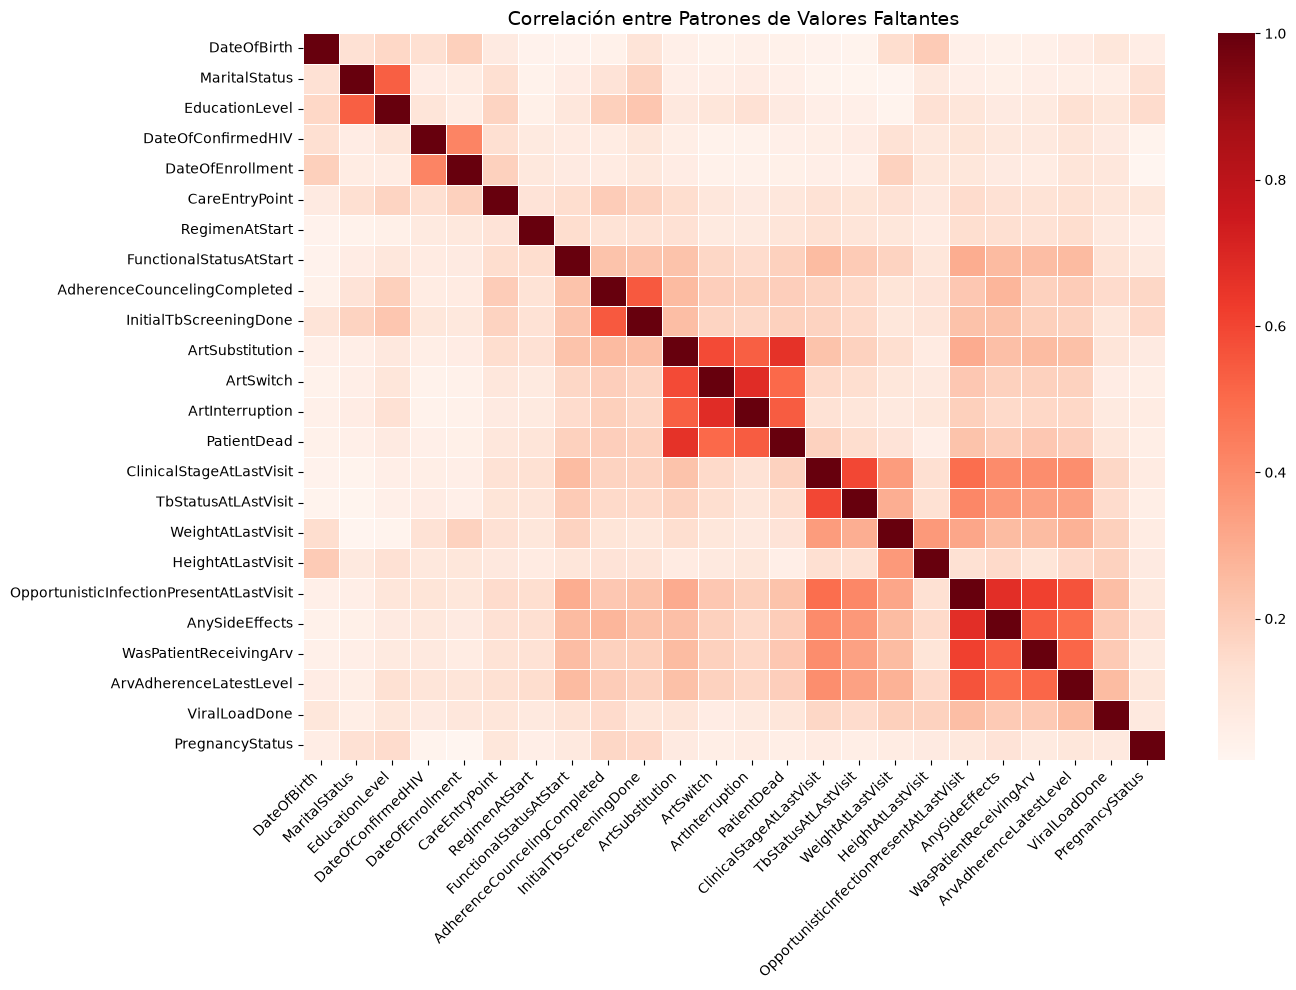

In [22]:
# Seleccionamos únicamente variables con valores nulos para el análisis de co-ocurrencia

variables_con_nulos = df.columns[df.isnull().any()].tolist()



# Creamos matriz booleana de nulos (1 = nulo, 0 = presente)

matriz_nulos = df[variables_con_nulos].isnull().astype(int)



# Calculamos correlación entre patrones de nulos

correlacion_nulos = matriz_nulos.corr()



# Visualizamos como heatmap

fig, ax = plt.subplots(figsize=(14, 10))

sns.heatmap(

    correlacion_nulos,

    cmap='Reds',

    ax=ax,

    linewidths=0.5,

    annot=False  # Con 30+ variables, los números se solapan — mejor sin anotaciones

)

ax.set_title('Correlación entre Patrones de Valores Faltantes', fontsize=14)

plt.xticks(rotation=45, ha='right')

plt.tight_layout()

plt.show()

,Variable,Q1,Q3,IQR,Límite Inferior,Límite Superior,N Outliers,Pct Outliers
2,HeightAtStart,158.000000,160.000000,2.000000,155.000000,163.000000,10353,37.94%
7,ViralLoad,63.000000,63.000000,0.000000,63.000000,63.000000,7155,26.22%
5,HeightAtLastVisit,150.000000,166.000000,16.000000,126.000000,190.000000,2631,17.27%
1,WeightAtStart,48.000000,64.000000,16.000000,24.000000,88.000000,2329,8.53%
3,Cd4AtStart,170.000000,383.000000,213.000000,-149.500000,702.500000,1916,7.02%
6,MostRecentCd4Count,288.000000,517.250000,229.250000,-55.880000,861.120000,1889,6.92%
4,WeightAtLastVisit,50.000000,69.000000,19.000000,21.500000,97.500000,1603,6.56%
0,Age,27.000000,41.000000,14.000000,6.000000,62.000000,1395,5.11%
8,Height_missing,0.000000,1.000000,1.000000,-1.500000,2.500000,0,0.00%
9,ViralLoad_missing,0.000000,1.000000,1.000000,-1.500000,2.500000,0,0.00%


/tmp/ipykernel_16309/3482351834.py:109: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(
/tmp/ipykernel_16309/3482351834.py:109: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(
/tmp/ipykernel_16309/3482351834.py:109: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(
/tmp/ipykernel_16309/3482351834.py:109: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(
/tmp/ipykernel_16309/3482351834.py:109: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed i

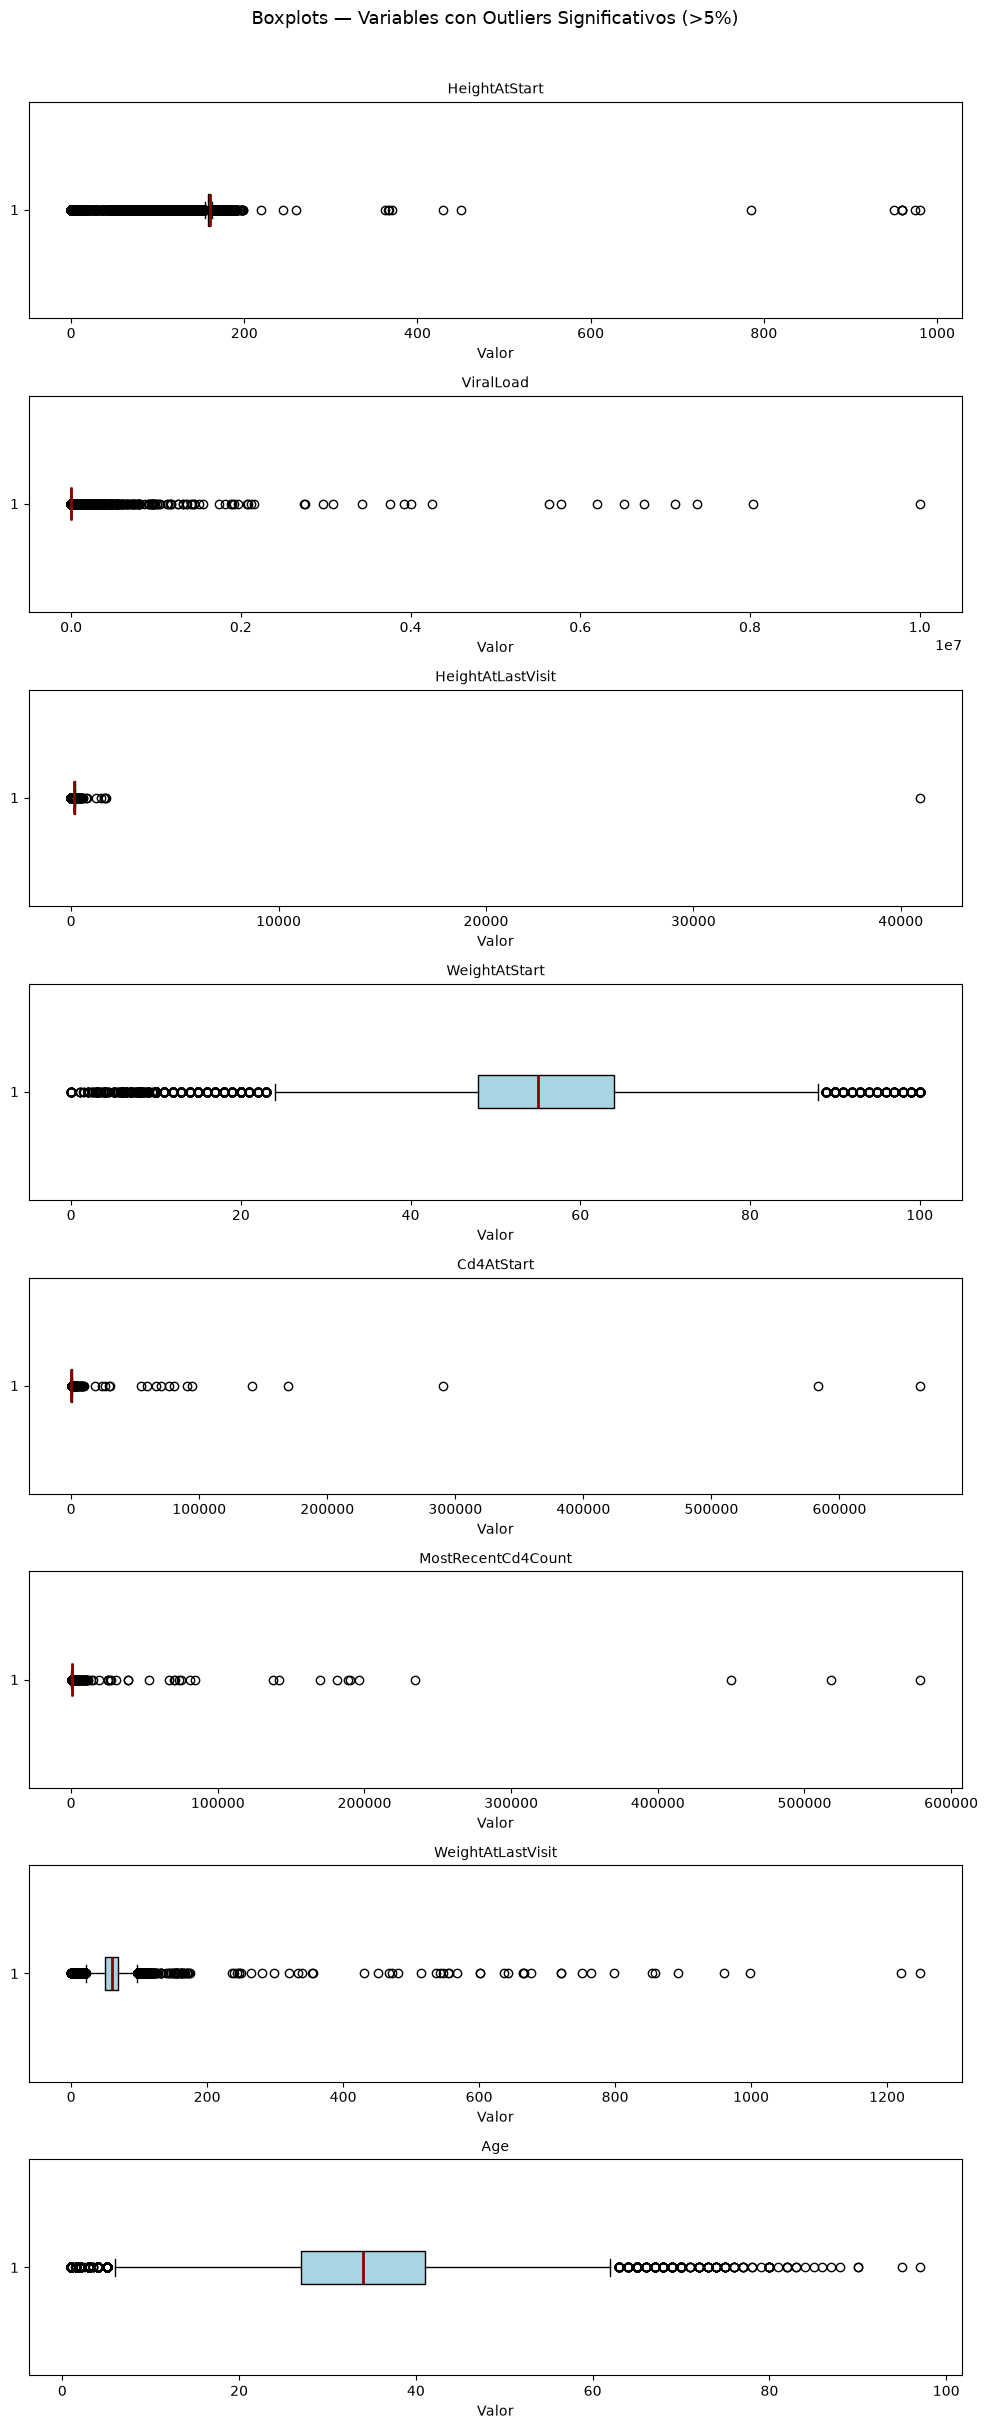

In [23]:
# Identificación de outliers mediante el método IQR

# Q1 = percentil 25, Q3 = percentil 75, IQR = rango intercuartílico



variables_numericas = df.select_dtypes(include=[np.number]).columns.tolist()



resumen_outliers = []



for var in variables_numericas:

    Q1 = df[var].quantile(0.25)

    Q3 = df[var].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR

    limite_superior = Q3 + 1.5 * IQR



    n_outliers = ((df[var] < limite_inferior) | (df[var] > limite_superior)).sum()

    pct_outliers = (n_outliers / df[var].count() * 100).round(2)



    resumen_outliers.append({

        'Variable': var,

        'Q1': round(Q1, 2),

        'Q3': round(Q3, 2),

        'IQR': round(IQR, 2),

        'Límite Inferior': round(limite_inferior, 2),

        'Límite Superior': round(limite_superior, 2),

        'N Outliers': n_outliers,

        'Pct Outliers': pct_outliers

    })



resumen_outliers = pd.DataFrame(resumen_outliers).sort_values('Pct Outliers', ascending=False)



display(

    resumen_outliers.style

    .background_gradient(subset=['Pct Outliers'], cmap='Reds')

    .format({'Pct Outliers': '{:.2f}%'})

    .set_caption('Detección de Outliers por Variable — Método IQR')

)

# Filtramos únicamente variables con porcentaje de outliers superior al 5%

# para enfocarnos en las que requieren atención real



variables_con_outliers = resumen_outliers[

    resumen_outliers['Pct Outliers'] > 5

]['Variable'].tolist()



fig, axes = plt.subplots(

    nrows=len(variables_con_outliers),

    ncols=1,

    figsize=(10, len(variables_con_outliers) * 3)

)



# Manejo del caso donde solo hay una variable

if len(variables_con_outliers) == 1:

    axes = [axes]



for i, var in enumerate(variables_con_outliers):

    axes[i].boxplot(

        df[var].dropna(),

        vert=False,

        patch_artist=True,

        boxprops=dict(facecolor='#a8d5e2'),

        medianprops=dict(color='darkred', linewidth=2)

    )

    axes[i].set_title(f'{var}', fontsize=10)

    axes[i].set_xlabel('Valor')



plt.suptitle('Boxplots — Variables con Outliers Significativos (>5%)',

             fontsize=13, y=1.01)

plt.tight_layout()

plt.show()

In [ ]:
#Variables redundantes (eliminación de variables)

cols_drop_redundant = [

    'HeightUnit',

    'Cd4Unit'      # unidad constante o irrelevante

]



df.drop(columns=cols_drop_redundant, inplace=True)

In [ ]:
#Variables complejas (eliminación de variables)

cols_drop_complex = [

    'FundingSources',

    'Occupation'       # Compleja de analizar sin recodificación

]



df.drop(columns=cols_drop_complex, inplace=True)

In [ ]:
# Tratamiento  ViralLoad

# Objetivo: convertir a variable numérica

# Problema: contiene valores no numéricos (object)



df['ViralLoad'] = pd.to_numeric(df['ViralLoad'], errors='coerce')

# Verificamos valores negativos en ViralLoad

print(f'Registros con ViralLoad negativo: {(df["ViralLoad"] < 0).sum()}')

print(df[df['ViralLoad'] < 0]['ViralLoad'].describe())

In [ ]:
df['ViralLoad_missing'] = df['ViralLoad'].isnull().astype(int)

print(f'Registros originalmente nulos en ViralLoad: {df["ViralLoad_missing"].sum()}')

In [ ]:
# Corrección de valores negativos en ViralLoad

# Clínicamente imposibles — se reemplazan con NaN y se reimputa con mediana

# Afecta únicamente 3 registros (0.01% del dataset)



df['ViralLoad'] = df['ViralLoad'].where(df['ViralLoad'] >= 0, other=np.nan)

df['ViralLoad'] = df['ViralLoad'].fillna(df['ViralLoad'].median())



print(f'Valores negativos restantes: {(df["ViralLoad"] < 0).sum()}')

In [ ]:
# Verificación: ViralLoad ya no tiene nulos (la imputación de la celda anterior
# a los valores negativos también cubrió los nulos originales del todo)

print(f'Nulos restantes en ViralLoad: {df["ViralLoad"].isnull().sum()}')

In [ ]:
print(f'Variables eliminadas: {len(cols_drop_high_nulls + cols_drop_redundant + cols_drop_complex)}')

print(f'Variables restantes: {df.shape[1]}')

In [ ]:
# Age — reemplazamos valores fuera de rango plausible con NaN

df['Age'] = df['Age'].where(

    (df['Age'] >= 1) & (df['Age'] <= 100),

    other=np.nan

)


In [24]:
# Contar y eliminar filas duplicadas
duplicados = df.duplicated().sum()
print(f'Registros duplicados: {duplicados}')
df = df.drop_duplicates()
print(f'Duplicados restantes: {df.duplicated().sum()}')

Registros duplicados: 66
Duplicados restantes: 0
